# Oil, Bitcoin & Equity Market Analysis

## 1. Titre et problématique

**Question centrale :** sur une période historique commune, quelles similitudes
et quelles divergences.observe-t-on entre trois marchés aux fonctionnements très
différents — le pétrole brut WTI, le Bitcoin (BTC/USD) et l'indice S&P 500 ?

Le projet est **descriptif et pédagogique**. Il compare des trajectoires, du
risque observé et des co-mouvements. Il ne prédit rien, ne recommande aucune
stratégie et n'établit aucune causalité (BR-017).

## 2. Objectifs et périmètre

Objectifs :

1. Récupérer trois séries documentées et traçables (fournisseur, identifiant, unité).
2. Contrôler la qualité des données (dates, doublons, valeurs manquantes, calendrier).
3. Comparer des évolutions relatives en base 100 (les niveaux bruts ne sont pas comparables).
4. Calculer rendements, volatilité, drawdown et corrélations avec des formules explicites.
5. Reproduire l'analyse dans un environnement documenté.

Périmètre : période cible `2020-01-01` → `2025-12-31` (bornes incluses), fréquence
journalière. Hors périmètre : conseil financier, prévision, données temps réel,
application web, base de données.

## 3. Sources et métadonnées

| Série | Fournisseur | Identifiant | Unité | Statut de vérification |
|---|---|---|---|---|
| `WTI` | FRED (source EIA) | `DCOILWTICO` | USD par baril (spot) | endpoint CSV testé, HTTP 200 |
| `BTC_USD` | Coinbase Exchange (API publique) | `BTC-USD` | USD par BTC | endpoint `candles` testé, HTTP 200 |
| `SP500` | FRED (S&P Dow Jones Indices) | `SP500` | points d'indice | endpoint CSV testé, HTTP 200 |

Points de vigilance documentés :

- `SP500` est un **indice de prix** : les dividendes n'en sont pas inclus (BR-018).
- `DCOILWTICO` est un **prix spot**, pas un contrat à terme.
- `BTC_USD` est le cours d'une **seule plateforme**, avec une clôture journalière UTC.
- Les conditions d'utilisation de FRED et de Coinbase **n'ont pas pu être lues**
  depuis cet environnement : elles doivent être vérifiées avant toute rediffusion.

## 4. Imports et configuration

Les calculs vivent dans `src/` : le notebook raconte, il ne réimplémente pas.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

from src import data_loader, metrics, pipeline, preprocessing, visualization

pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 30)

START = "2020-01-01"
END = "2025-12-31"
RAW_DIR = PROJECT_ROOT / "data" / "raw"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
FIGURES_DIR = PROJECT_ROOT / "outputs" / "figures"
PERIODS_PER_YEAR = pipeline.PERIODS_PER_YEAR
BITCOIN_PERIODS_PER_YEAR = pipeline.BITCOIN_PERIODS_PER_YEAR

print("Python :", sys.version.split()[0])
print("pandas :", pd.__version__)
print("Période d'étude :", START, "→", END)
print("Fournisseurs déclarés :", sorted(data_loader.SERIES))

Python : 3.13.12
pandas : 2.3.3
Période d'étude : 2020-01-01 → 2025-12-31
Fournisseurs déclarés : ['BTC_USD', 'SP500', 'WTI']


In [2]:
registry = pd.DataFrame(
    [data_loader.describe_series(asset) for asset in data_loader.SERIES]
).set_index("asset")[["provider", "series_id", "unit", "frequency", "close_convention"]]
registry

,provider,series_id,unit,frequency,close_convention
asset,,,,,
WTI,FRED (U.S. Energy Information Administration),DCOILWTICO,USD par baril,journalière (jours ouvrés US),"cours spot quotidien, heure de clôture non pub..."
BTC_USD,Coinbase Exchange (public market data API),BTC-USD,USD par BTC,journalière (7j/7),"bougie quotidienne UTC (granularité 86400 s), ..."
SP500,"FRED (S&P Dow Jones Indices, LLC)",SP500,points d'indice,journalière (jours ouvrés US),"clôture officielle du marché, heure non publié..."


## 5. Récupération des données

Le pipeline télécharge les trois séries, enregistre les métadonnées de collecte,
contrôle le schéma, audite la qualité, filtre la période cible et aligne les
calendriers. Il n'existe **aucune donnée de secours** : si une source est
injoignable, l'exécution s'arrête avec un message explicite (BR-015). Le repli
éventuel porte sur des copies **réellement téléchargées** présentes dans `data/raw/`.

In [3]:
OFFLINE = False  # True = réutilise les copies locales de data/raw/

try:
    result = pipeline.run_pipeline(START, END, offline=OFFLINE)
except data_loader.DataSourceError as error:
    print("ÉCHEC DE RÉCUPÉRATION :", error)
    cached = all((RAW_DIR / f"{asset}.csv").exists() for asset in pipeline.DEFAULT_ASSETS)
    if not cached:
        raise
    print("Copies locales détectées dans data/raw/ : reprise en mode hors ligne.")
    result = pipeline.run_pipeline(START, END, offline=True)

print("Observations brutes téléchargées :", result.raw_observations)
print("Observations alignées           :", result.alignment["observations_aligned"])

Observations brutes téléchargées : {'WTI': 1565, 'BTC_USD': 2185, 'SP500': 1565}
Observations alignées           : 1496


/home/kiddy/Téléchargements/oil-bitcoin-equity-analysis-docs/src/pipeline.py:183: RuntimeWarning: date
2020-01-02    61.17
2020-01-03    63.00
2020-01-06    63.27
2020-01-07    62.70
2020-01-08    59.65
              ...  
2025-12-24    58.72
2025-12-26    56.60
2025-12-29    57.89
2025-12-30    57.79
2025-12-31    57.26
Name: WTI, Length: 1496, dtype: float64 : 2 rendement(s) logarithmique(s) non définis, remplacés par NaN (prix non strictement positif).
  lambda column: metrics.log_returns(column, on_invalid="nan", name=str(column))


In [4]:
metadata_table = pd.DataFrame(result.metadata).T[
    [
        "provider",
        "series_id",
        "unit",
        "currency",
        "frequency",
        "rows_returned",
        "first_observation",
        "last_observation",
        "retrieved_at",
    ]
]
metadata_table

,provider,series_id,unit,currency,frequency,rows_returned,first_observation,last_observation,retrieved_at
WTI,FRED (U.S. Energy Information Administration),DCOILWTICO,USD par baril,USD,journalière (jours ouvrés US),1565,2020-01-02,2025-12-31,2026-10-10T14:30:51+00:00
BTC_USD,Coinbase Exchange (public market data API),BTC-USD,USD par BTC,USD,journalière (7j/7),2185,2020-01-01,2025-12-31,2026-10-10T14:32:19+00:00
SP500,"FRED (S&P Dow Jones Indices, LLC)",SP500,points d'indice,n/a (indice),journalière (jours ouvrés US),1565,2020-01-02,2025-12-31,2026-10-10T14:32:45+00:00


## 6. Audit qualité

Ce rapport **signale**, il ne corrige pas : aucune valeur manquante n'est
interpolée ni reconstituée (BR-008), aucun outlier n'est supprimé.

In [5]:
quality_table = pd.DataFrame(result.quality).T[
    [
        "provider",
        "series_id",
        "rows",
        "first_date",
        "last_date",
        "missing_close",
        "missing_close_pct",
        "duplicate_dates",
        "non_positive",
        "observed_gap_days_median",
        "observed_gap_days_max",
        "excluded_by_period_filter",
        "dropped_missing_in_window",
    ]
]
quality_table

,provider,series_id,rows,first_date,last_date,missing_close,missing_close_pct,duplicate_dates,non_positive,observed_gap_days_median,observed_gap_days_max,excluded_by_period_filter,dropped_missing_in_window
WTI,FRED (U.S. Energy Information Administration),DCOILWTICO,1565,2020-01-02,2025-12-31,65,4.153355,0,1,1.0,3.0,0,65
BTC_USD,Coinbase Exchange (public market data API),BTC-USD,2185,2020-01-01,2025-12-31,0,0.0,0,0,1.0,2.0,0,0
SP500,"FRED (S&P Dow Jones Indices, LLC)",SP500,1565,2020-01-02,2025-12-31,57,3.642173,0,0,1.0,3.0,0,57


In [6]:
extremes = pd.DataFrame(
    {
        asset: {
            "moves > 20 %": report["moves_over_threshold"],
            "plus forte variation": report["largest_move"],
            "min": report["min_close"],
            "max": report["max_close"],
            "dernière valeur": report["last_close"],
        }
        for asset, report in result.quality.items()
    }
).T
extremes

,moves > 20 %,plus forte variation,min,max,dernière valeur
WTI,12.0,3.019661,-36.98,123.64,57.26
BTC_USD,1.0,0.388124,4857.10,124720.09,87497.94
SP500,0.0,0.119841,2237.40,6932.05,6845.50


## 7. Nettoyage, calendriers et alignement

Règle d'alignement retenue : **intersection des dates observées** (BR-008, BR-009).
Aucune valeur n'est reconduite d'un jour sur l'autre : une date absente d'une
série exclut simplement cette date du panel commun.

In [7]:
alignment_table = pd.DataFrame(
    {
        "observations avant alignement": result.alignment["observations_before"],
        "observations alignées": result.alignment["observations_aligned"],
        "observations perdues": result.alignment["observations_lost"],
    }
).T
alignment_table

,WTI,BTC_USD,SP500
observations avant alignement,1500,2185,1508
observations alignées,1496,1496,1496
observations perdues,4,689,12


In [8]:
calendar_table = pd.DataFrame(
    {
        asset: pd.to_datetime(panel["date"])
        .dt.dayofweek.value_counts()
        .sort_index()
        .reindex(range(7), fill_value=0)
        for asset, panel in result.alignment_raw.items()
    }
)
calendar_table.index = ["lundi", "mardi", "mercredi", "jeudi", "vendredi", "samedi", "dimanche"]
calendar_table

,WTI,BTC_USD,SP500
lundi,277,312,281
mardi,311,312,312
mercredi,310,313,310
jeudi,303,312,303
vendredi,299,312,302
samedi,0,312,0
dimanche,0,312,0


In [9]:
gap_table = (
    pd.DataFrame(
        {
            asset: pd.Series(gaps).value_counts().sort_index()
            for asset, gaps in result.alignment_gaps.items()
        }
    )
    .fillna(0)
    .astype(int)
)
gap_table.columns = [f"{column} (jours)" for column in gap_table.columns]
gap_table

,WTI (jours),BTC_USD (jours),SP500 (jours)
date,,,
1,1173,2177,1180
2,13,7,14
3,263,0,270
4,48,0,43
5,2,0,0


Lecture du tableau des écarts : `0` jour correspond aux dates consécutives,
`3` jours au passage du vendredi au lundi, etc. Des écarts supérieurs à
`7` jours révèlent des jours fériés non couverts par les marchés américains.

> **Instant de clôture (BR-010).** Une date commune ne signifie pas le même
> instant : le S&P 500 et le WTI clôturent pendant la séance américaine, Bitcoin
> clôture à minuit UTC. Les rendements d'un même jour portent donc sur des
> fenêtres temporelles légèrement différentes.

## 8. Visualisation des prix bruts

Les niveaux bruts ne sont pas comparables : USD/baril, USD/BTC et points
d'indice n'ont ni la même unité ni la même échelle (BR-003). Chaque série est
donc tracée séparément, avec son unité et sa source.

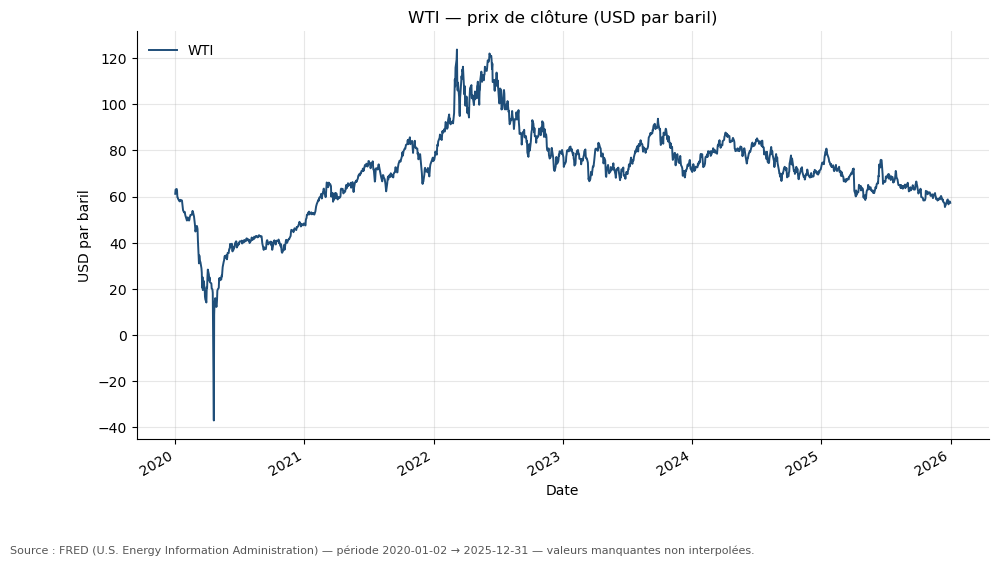

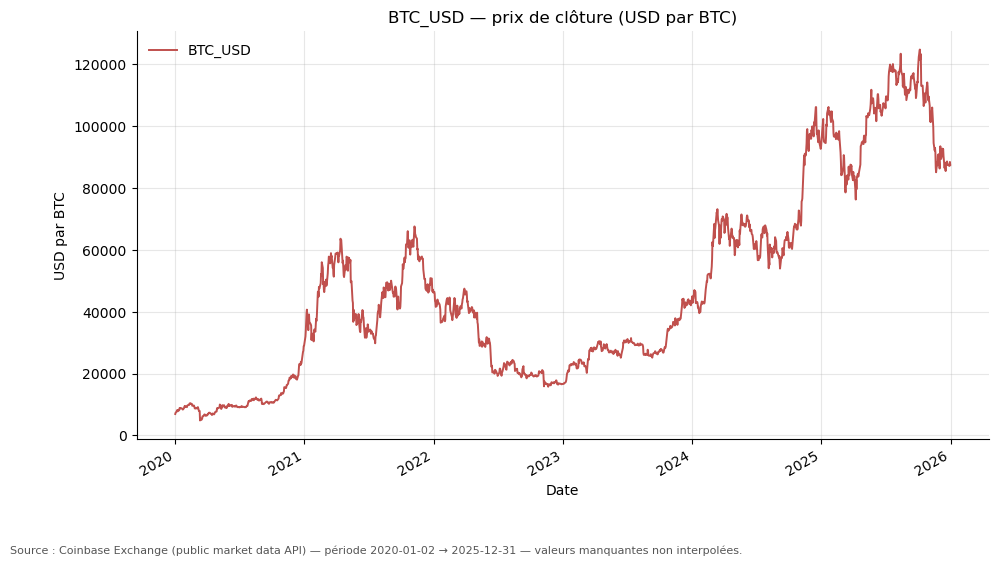

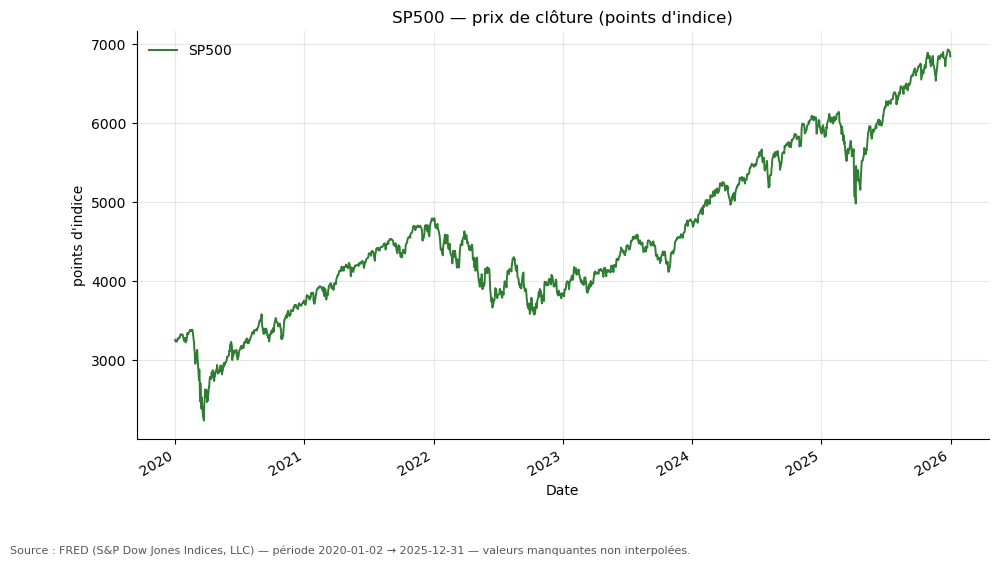

In [10]:
for asset, prices in result.prices.items():
    spec = data_loader.SERIES[asset]
    fig = visualization.plot_price(prices, asset=asset, unit=spec.unit, provider=spec.provider)
    display(fig)
    plt.close(fig)

## 9. Comparaison en base 100

`indice_t = prix_t / prix_base * 100`, la base étant la **première observation
valide de la fenêtre commune**. Le tableau ci-dessous affiche la date et la
valeur de référence de chaque série (BR-004).

In [11]:
base_table = pd.DataFrame(result.bases).T
base_table

,base_date,base_value,base_index
WTI,2020-01-02,61.17,100.0
BTC_USD,2020-01-02,6945.02,100.0
SP500,2020-01-02,3257.85,100.0


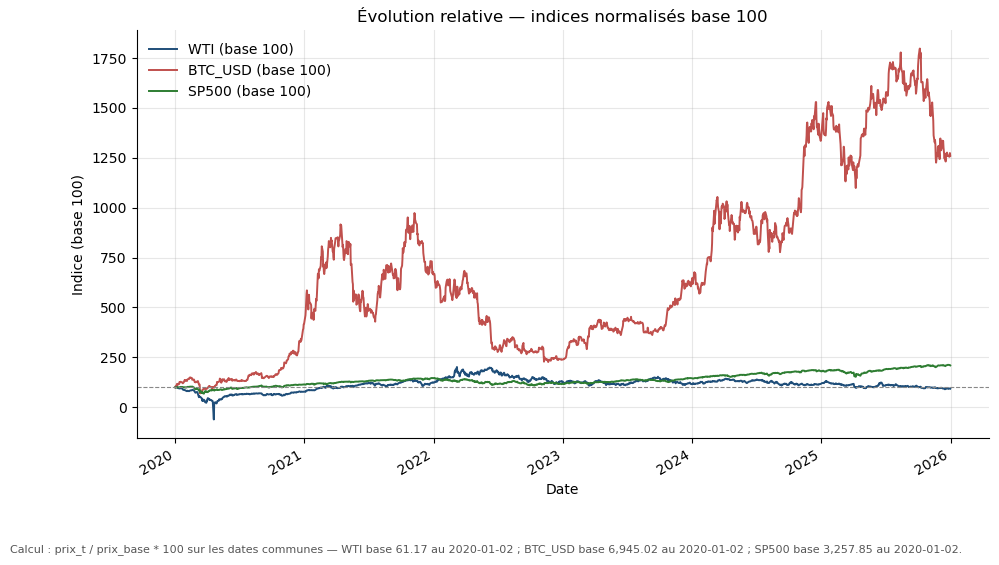

In [12]:
fig = visualization.plot_normalized_index(result.indices, bases=result.bases)
display(fig)
visualization.save_figure(fig, FIGURES_DIR / "01_indices_base100.png")
plt.close(fig)

## 10. Analyse des rendements

Rendement simple : `r_t = P_t / P_{t-1} - 1` (BR-005).
Rendement logarithmique : `ln(P_t / P_{t-1})`, uniquement si les deux prix sont
strictement positifs (BR-006).

Un rendement situé à plus de `7` jours de son prédécesseur est mis à `NaN` :
il représenterait un horizon différent d'une séance de marché, donc un
rendement non comparable aux autres.

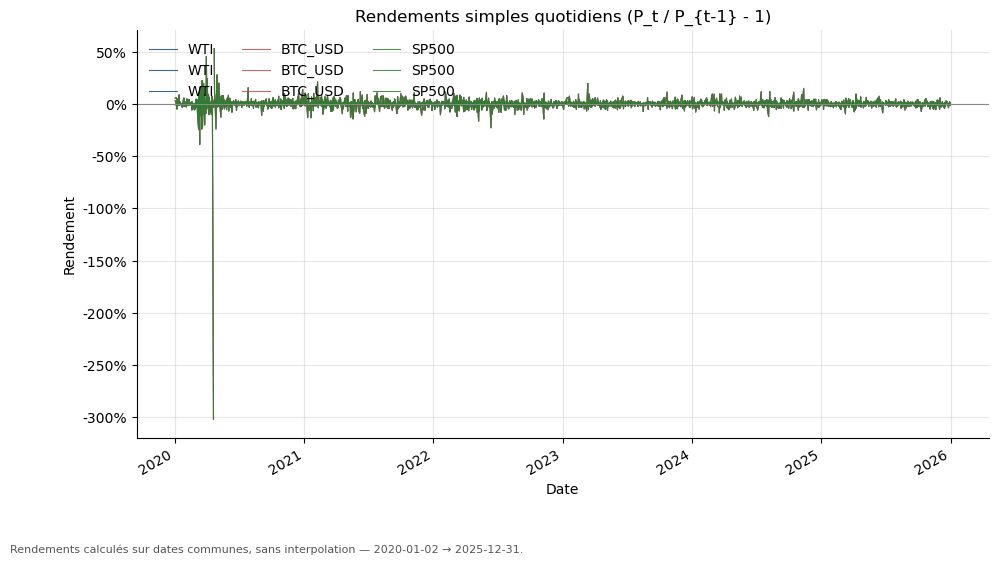

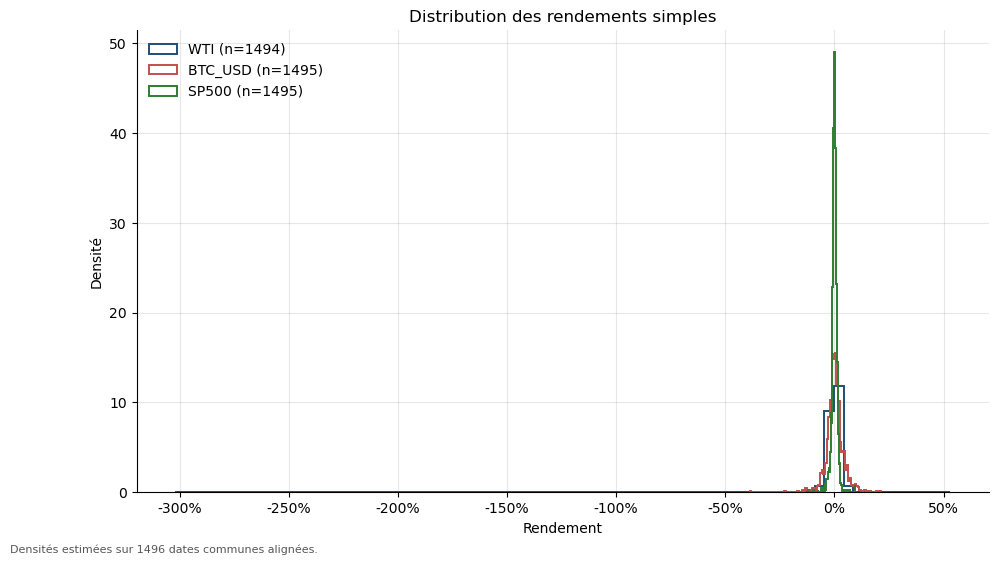

In [13]:
fig = visualization.plot_returns(result.returns)
display(fig)
visualization.save_figure(fig, FIGURES_DIR / "02_rendements.png")
plt.close(fig)

fig = visualization.plot_return_distribution(result.returns)
display(fig)
visualization.save_figure(fig, FIGURES_DIR / "03_distribution_rendements.png")
plt.close(fig)

In [14]:
comparison = pd.DataFrame(
    {
        "rendement simple": result.returns.mean(),
        "rendement logarithmique": result.log_returns.mean(),
    }
)
comparison.index.name = "asset"
comparison

,rendement simple,rendement logarithmique
asset,,
WTI,-0.000955,0.000438
BTC_USD,0.002478,0.001695
SP500,0.000585,0.000497


### Cas particulier : un prix spot négatif

La règle BR-014 impose de signaler les prix nuls ou négatifs. Le contrôle qualité
en a détecté : le voici localisé dans le panel aligné, avec son effet sur les
rendements (un rendement simple et un rendement logarithmique sont non calculables
de part et d'autre de ce prix, car la formule exige des prix strictement positifs).

In [15]:
non_positive_rows = []
for asset in result.alignment_raw:
    series = result.alignment_raw[asset]
    mask = series["close"] <= 0
    for _, row in series.loc[mask].iterrows():
        non_positive_rows.append(
            {"asset": asset, "date": row["date"].date(), "close": row["close"]}
        )
non_positive = pd.DataFrame(non_positive_rows)
non_positive

,asset,date,close
0,WTI,2020-04-20,-36.98


In [16]:
used = pd.DataFrame(
    {
        "prix alignés": result.prices.count(),
        "rendements calculés": result.returns.count(),
        "rendements écartés (prix non positif ou écart > 7 j)": result.prices.shape[0]
        - result.returns.count(),
    }
)
used.index.name = "asset"
used

,prix alignés,rendements calculés,rendements écartés (prix non positif ou écart > 7 j)
asset,,,
WTI,1496,1494,2
BTC_USD,1496,1495,1
SP500,1496,1495,1


## 11. Statistiques descriptives

Toutes les valeurs sont exprimées en pourcentage des rendements simples
alignés. Le nombre d'observations réellement utilisé est indiqué pour chaque
série : c'est un point de contrôle, pas un détail décoratif.

In [17]:
stats = metrics.describe_returns_table(result.returns)
stats

,observations,mean,median,std,min,q05,q25,q75,q95,max,skew,positive_share,unit
WTI,1494,-0.095472,0.137007,8.62227,-301.966139,-4.105335,-1.322305,1.502712,3.786094,53.08642,-28.515941,52.677376,%
BTC_USD,1495,0.247767,0.145789,3.912031,-38.812429,-5.632055,-1.620991,2.054515,6.510618,21.238041,-0.498737,51.705686,%
SP500,1495,0.058457,0.09927,1.322854,-11.98405,-1.838366,-0.490901,0.691965,1.768561,9.51539,-0.333668,54.381271,%


In [18]:
positive_days = pd.DataFrame(
    {
        "jours de hausse (%)": (result.returns > 0).sum(),
        "jours de baisse (%)": (result.returns < 0).sum(),
        "observations": result.returns.count(),
    }
)
positive_days.index.name = "asset"
positive_days

,jours de hausse (%),jours de baisse (%),observations
asset,,,
WTI,787,702,1494
BTC_USD,773,722,1495
SP500,813,682,1495


## 12. Volatilité et drawdown

**Volatilité (BR-011).** Deux quantités distinctes :

- l'écart-type **observé** des rendements quotidiens ;
- la volatilité **annualisée** `std × √N`.

Sur le panel aligné, toutes les séries partagent le même calendrier de séances :
`N = 252` pour les trois, sinon la comparaison serait faussée. Bitcoin qui cote
365 jours par an verrait sa volatilité annuelle passer d'environ ×√365 à ×√252
si on l'analysait seul sur son calendrier natif ; les deux valeurs sont données
pour information.

In [19]:
volatility = pd.DataFrame(
    {
        "écart-type quotidien (%)": result.returns.std(ddof=1) * 100,
        f"volatilité annualisée N={PERIODS_PER_YEAR} (%)": {
            asset: metrics.annualized_volatility(
                result.returns[asset], periods_per_year=PERIODS_PER_YEAR
            )
            * 100
            for asset in result.returns.columns
        },
        f"volatilité informative N={BITCOIN_PERIODS_PER_YEAR} (%)": {
            asset: metrics.annualized_volatility(
                result.returns[asset], periods_per_year=BITCOIN_PERIODS_PER_YEAR
            )
            * 100
            for asset in result.returns.columns
        },
    }
)
volatility.index.name = "asset"
volatility.round(2)

,écart-type quotidien (%),volatilité annualisée N=252 (%),volatilité informative N=365 (%)
asset,,,
WTI,8.62,136.87,164.73
BTC_USD,3.91,62.10,74.74
SP500,1.32,21.00,25.27


In [20]:
drawdown_rows = {}
for asset in result.indices.columns:
    info = metrics.max_drawdown(result.indices[asset])
    drawdown_rows[asset] = {
        "max_drawdown": info["max_drawdown"],
        "peak_value": info["peak_value"],
        "trough_value": info["trough_value"],
        "date du sommet": info["peak_date"].date(),
        "date du creux": info["trough_date"].date(),
    }
drawdown_table = pd.DataFrame(drawdown_rows).T
drawdown_table.round(4)

,max_drawdown,peak_value,trough_value,date du sommet,date du creux
WTI,-1.584479,103.433055,-60.454471,2020-01-06,2020-04-20
BTC_USD,-0.766706,972.709078,226.927208,2021-11-08,2022-11-21
SP500,-0.33925,103.93818,68.677195,2020-02-19,2020-03-23


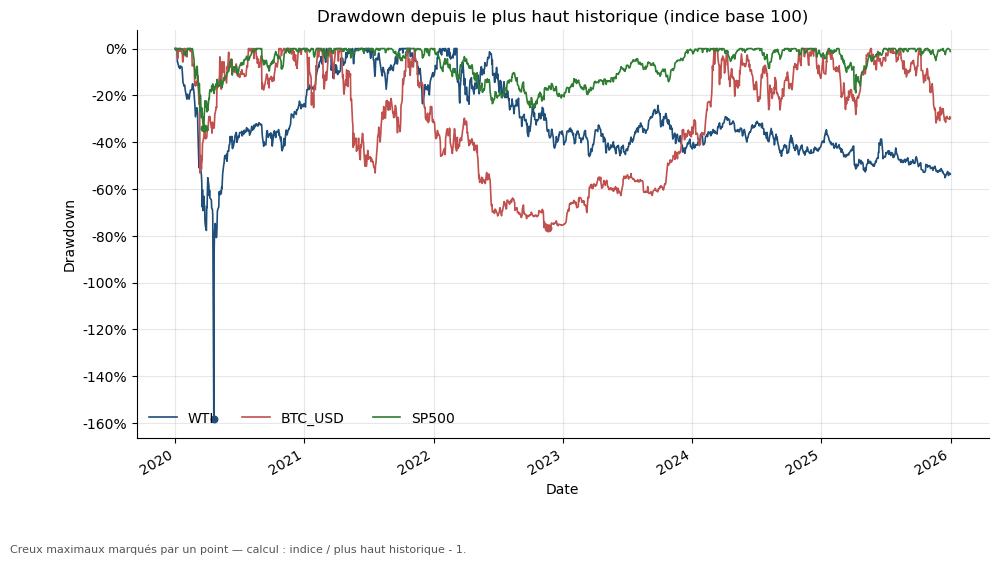

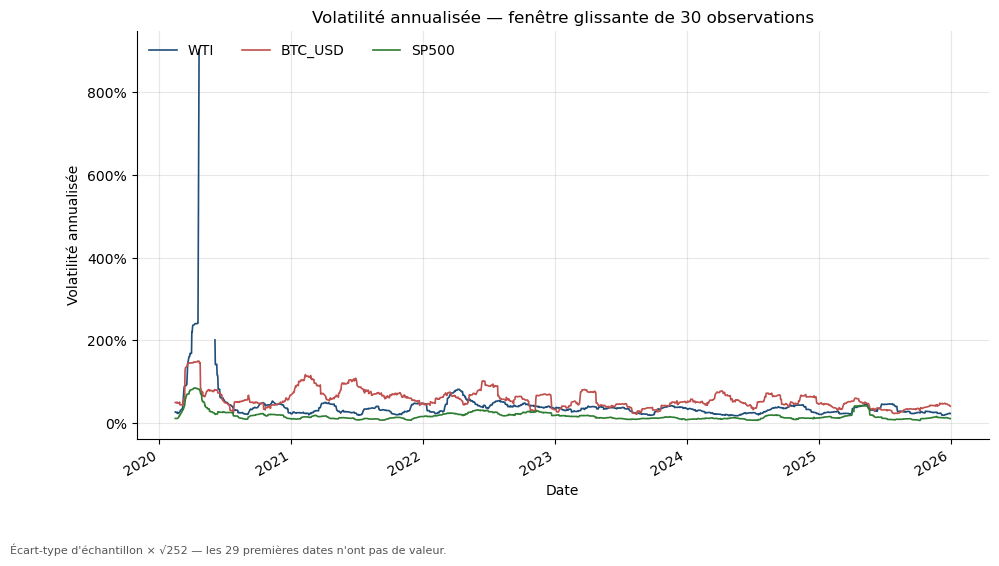

In [21]:
fig = visualization.plot_drawdown(result.drawdowns)
display(fig)
visualization.save_figure(fig, FIGURES_DIR / "04_drawdown.png")
plt.close(fig)

fig = visualization.plot_rolling_volatility(
    result.rolling_volatility, window=pipeline.ROLLING_WINDOW
)
display(fig)
visualization.save_figure(fig, FIGURES_DIR / "05_volatilite_glissante.png")
plt.close(fig)

## 13. Matrice de corrélation

Corrélation de **Pearson sur les rendements alignés**, jamais sur les prix
( BR-012). Le nombre d'observations appariées est affiché.

In [22]:
common_counts = pd.Series(
    {asset: int(result.returns.dropna().shape[0]) for asset in result.returns.columns}
)
common_counts.index.name = "asset"
common_counts

asset
WTI        1494
BTC_USD    1494
SP500      1494
dtype: int64

In [23]:
correlation = metrics.correlation_matrix(result.returns.dropna())
correlation.round(3)

asset,WTI,BTC_USD,SP500
asset,,,
WTI,1.000,0.054,0.097
BTC_USD,0.054,1.000,0.380
SP500,0.097,0.380,1.000


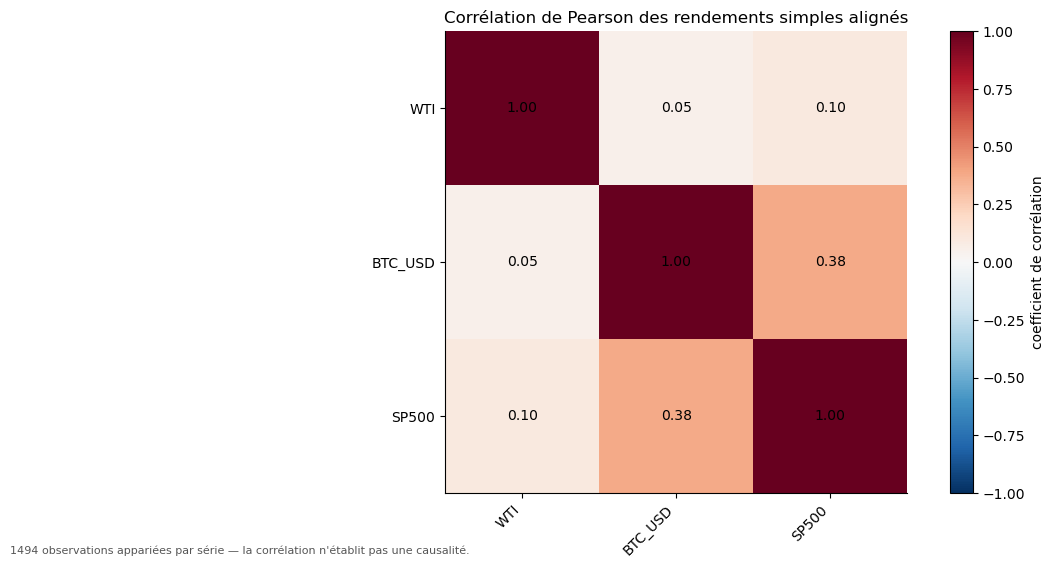

In [24]:
fig = visualization.plot_correlation_heatmap(
    correlation, n_observations=int(result.returns.dropna().shape[0])
)
display(fig)
visualization.save_figure(fig, FIGURES_DIR / "06_correlation.png")
plt.close(fig)

> **Lecture prudente des chiffres du WTI.** Le 2020-04-20, le prix spot du WTI
> est négatif (BR-014). Les deux rendements adjacents sont donc non calculables
> (BR-005 et BR-006) et le drawdown calculé sur l'indice base 100 passe sous -100 %.
> Les deux lignes WTI ci-dessus doivent être lues comme **propriétés de cette série
> histórica**, pas comme des mesures de risque directement comparables aux deux autres.

### Sensibilité : alignement hebdomadaire

L'ADR-002 demande de vérifier si les résultats dépendent fortement de la
fréquence. Voici les mêmes statistiques sur une agrégation hebdomadaire (dernière
observation de chaque semaine ISO, sans fabrication de valeur).

In [25]:
weekly_frames = {}
for asset, frame in result.alignment_raw.items():
    weekly = preprocessing.resample_weekly(frame)
    weekly.index.name = "date"
    weekly_frames[asset] = weekly.reset_index()
weekly_panel = preprocessing.align_common_dates(weekly_frames)
weekly_returns = weekly_panel.apply(
    lambda column: metrics.simple_returns(column, max_gap_days=14.0, name=str(column))
)
weekly_summary = pd.DataFrame(
    {
        "observations": weekly_returns.count(),
        "volatilité hebdomadaire (%)": (weekly_returns.std(ddof=1) * 100).round(2),
        "volatilité annualisée N=52 (%)": {
            asset: metrics.annualized_volatility(weekly_returns[asset], periods_per_year=52) * 100
            for asset in weekly_returns.columns
        },
    }
)
weekly_summary.round(2)

,observations,volatilité hebdomadaire (%),volatilité annualisée N=52 (%)
WTI,313,8.00,57.67
BTC_USD,313,8.14,58.68
SP500,313,2.72,19.58


In [26]:
weekly_correlation = metrics.correlation_matrix(weekly_returns.dropna()).round(3)
weekly_correlation

,WTI,BTC_USD,SP500
WTI,1.000,0.18,0.168
BTC_USD,0.180,1.00,0.300
SP500,0.168,0.30,1.000


## 14. Interprétation chiffrée

Les phrases ci-dessous sont **construites à partir des résultats calculés dans
ce notebook** : aucun chiffre n'est écrit à la main.

In [27]:
first_date = result.indices.index[0].date()
last_date = result.indices.index[-1].date()
n_dates = len(result.indices)
n_obs = int(result.returns.dropna().shape[0])

lines = []
lines.append("### Période et observations")
lines.append("")
lines.append(
    f"- Panel commun du **{first_date}** au **{last_date}** : **{n_dates} dates communes** "
    f"aux trois séries, dont **{n_obs}** avec des rendements complets pour les trois."
)
lines.append(
    "- Observations téléchargées avant alignement : "
    + ", ".join(f"{asset} {count}" for asset, count in result.raw_observations.items())
    + "."
)
lines.append(
    "- Observations perdues par l'intersection des calendriers : "
    + ", ".join(
        f"{asset} {loss}" for asset, loss in result.alignment["observations_lost"].items() if loss
    )
    + "."
)

lines.append("")
lines.append("### Performance cumulée (base 100)")
lines.append("")
for asset in result.indices.columns:
    start_value, end_value = result.indices[asset].iloc[0], result.indices[asset].iloc[-1]
    change = (end_value / start_value - 1) * 100
    lines.append(
        f"- **{asset}** : {start_value:.1f} → {end_value:.1f}, soit **{change:+.1f} %** sur la période."
    )

lines.append("")
lines.append("### Risque observé")
lines.append("")
if any(
    info["max_drawdown"] < -1
    for info in (metrics.max_drawdown(result.indices[a]) for a in result.indices.columns)
):
    lines.append(
        "> **Avertissement WTI.** Le drawdown du WTI dépasse -100 % : cet artefact vient "
        "du prix spot négatif du 2020-04-20. Une richesse ne peut pas être négative ; "
        "la série est ici l'indice base 100 du prix spot. Ce chiffre mesure donc un "
        "événement extrême de la série, pas une perte réellement finançable."
    )
    lines.append("")
lines.append("")
for asset in result.returns.columns:
    vol = metrics.annualized_volatility(result.returns[asset]) * 100
    drawdown = metrics.max_drawdown(result.indices[asset])["max_drawdown"] * 100
    lines.append(
        f"- **{asset}** : volatilité annualisée **{vol:.1f} %**, drawdown maximal "
        f"**{drawdown:.1f} %**, {stats.loc[asset, 'positive_share']:.1f} % de séances en hausse."
    )

lines.append("")
lines.append(
    "- Rendements effectivement calculés : "
    + ", ".join(f"{asset} {count}" for asset, count in result.returns.count().items())
    + " (les écarts correspondent aux prix non positifs et aux week-ends absents du panel)."
)

lines.append("")
lines.append("### Co-mouvements")
lines.append("")
pairs = [
    ("WTI", "BTC_USD"),
    ("WTI", "SP500"),
    ("BTC_USD", "SP500"),
]
for left, right in pairs:
    value = correlation.loc[left, right]
    weekly_value = weekly_correlation.loc[left, right]
    lines.append(
        f"- **{left} / {right}** : Pearson **{value:+.2f}** en quotidien, "
        f"**{weekly_value:+.2f}** en hebdomadaire (n = {n_obs} séances appariées)."
    )

lines.append("")
lines.append(
    "Ces coefficients décrivent une **co-occurrence temporelle** sur la période "
    "étudiée. Ils ne démontrent aucune relation causale (BR-017) et peuvent varier "
    "fortement hors de l'intervalle 2020-2025."
)
print("\n".join(lines))

### Période et observations

- Panel commun du **2020-01-02** au **2025-12-31** : **1496 dates communes** aux trois séries, dont **1494** avec des rendements complets pour les trois.
- Observations téléchargées avant alignement : WTI 1565, BTC_USD 2185, SP500 1565.
- Observations perdues par l'intersection des calendriers : WTI 4, BTC_USD 689, SP500 12.

### Performance cumulée (base 100)

- **WTI** : 100.0 → 93.6, soit **-6.4 %** sur la période.
- **BTC_USD** : 100.0 → 1259.9, soit **+1159.9 %** sur la période.
- **SP500** : 100.0 → 210.1, soit **+110.1 %** sur la période.

### Risque observé

> **Avertissement WTI.** Le drawdown du WTI dépasse -100 % : cet artefact vient du prix spot négatif du 2020-04-20. Une richesse ne peut pas être négative ; la série est ici l'indice base 100 du prix spot. Ce chiffre mesure donc un événement extrême de la série, pas une perte réellement finançable.


- **WTI** : volatilité annualisée **136.9 %**, drawdown maximal **-158.4 %**, 52.7 % de séances 

## 15. Limites de l'analyse

1. **Calendriers et clôtures (BR-010).** Une date commune ne signifie pas le même
   instant : séance américaine pour le S&P 500 et le WTI, minuit UTC pour Bitcoin.
2. **Valeurs manquantes.** Les jours sans cotation côté FRED ne sont ni interpolés
   ni reconstitués : ils retirent des dates au panel commun, ce qui réduit
   l'échantillon.
3. **Définitions de prix.** Le WTI est un prix spot, pas un contrat à terme ; le
   S&P 500 est un indice de prix sans dividendes ; le Bitcoin est le cours d'une
   seule plateforme.
4. **Fréquence d'échantillonnage.** Un rendement quotidien mesure des
   sous-ensembles d'intraday différents selon l'actif ; la comparaison est donc
   imparfaite par construction.
5. **Non-stationnarité.** Volatilité, moyenne et corrélation évoluent dans le
   temps (crash de 2020, remontée 2021-2022, krach 2022, période 2023-2025) ;
   les statistiques résument l'ensemble de la période sans décrire ces régimes.
6. **Échantillon unique.** Six années ne suffisent pas à conclure sur le
   comportement de long terme de Bitcoin.
7. **Données révisables.** Les fournisseurs peuvent corriger leurs séries : une
   reproduction future peut différer légèrement (BR-019).
8. **Aucune causalité.** Corrélation et co-mouvements ne prouvent aucun lien de
   cause à effet.

## 16. Conclusion et pistes d'amélioration

**Ce que l'analyse permet de dire** : trois actifs dont les prix bruts n'ont
rien de comparable convergent vers des indices base 100 qui divergeant fortement,
avec des niveaux de volatilité et de perte maximale très différents et des
co-mouvements statistiques de modestes à faibles. Les valeurs exactes sont celles
imprimées en section 14, calculées dans ce notebook.

**Limites rappelées** : conclusions descriptives, période biaisée par les
événements 2020-2025, clôtures non simultanées, aucune conclusion causale.

**Pistes d'amélioration** :

- tester d'autres fournisseurs BTC (Kraken, aggregate de plusieurs plateformes) ;
- ajouter une analyse de sensibilité sur la fenêtre de début et sur la fréquence ;
- introduire des rendements logarithmiques dans les graphiques de distribution ;
- calculer une volatilité réalisée à partir de données intraday ;
- distinguer l'indice de prix d'un indice de rendement total (dividendes) ;
- automatiser un test d'intégration réseau, exécuté séparément de la suite unitaire.